# Imports and Data

In [15]:
from pathlib import Path

import snntorch as snn
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import snntorch.spikeplot as splt

from torchvision import datasets, transforms
from snntorch import utils, spikegen
from torch.utils.data import DataLoader
from IPython.display import HTML, display

In [16]:
batch_size = 128 # size of batches used by the loader
num_steps = 100 # Temporal Dynamics for whole tutorial
num_classes = 10 # MNIST has 10 outputs
subset_loaded = 10 # Number of datapoints to use for visuals
dtype = torch.float # Torch preset for datatype being loaded

In [17]:
# Directory paths
project_root = next(path for path in (Path.cwd(), *Path.cwd().parents)if (path / "pyproject.toml").is_file())
data_path = project_root / "data" / "raw"
data_path.mkdir(parents=True, exist_ok=True)
figure_path = project_root / "report" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

In [18]:
# Load Dataset using transform specified by tutorial
transform = transforms.Compose([
    transforms.Resize((28,28)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0,), (1,))])

mnist_train = utils.data_subset(datasets.MNIST(data_path, train=True, download=True, transform=transform), subset_loaded)
train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)
print(f"Size of MNIST_train: {len(mnist_train)}")

Size of MNIST_train: 6000


# Tutorial 1 - Spike Encoding

Here we look at what rate coding is, just turing each numerical value into the probability p that a spike is produced in the spike train at that given point. This can be sampled to make many frames, each drawing from the created Bernoullis for each vector component.

In [19]:
raw_vector = torch.ones(num_steps)*0.5 # create vector filled with 0.5, so probability 0.5 at each step
rate_coded_vector = torch.bernoulli(raw_vector) # pass each sample through a Bernoulli trial

print(f"Converted vector: {rate_coded_vector}")
print(f"The output is spiking {rate_coded_vector.sum()*100/len(rate_coded_vector):.2f}% of the time.")

Converted vector: tensor([0., 0., 1., 0., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 0., 1., 0., 1.,
        0., 1., 0., 1., 1., 1., 0., 1., 0., 0., 1., 1., 1., 1., 1., 0., 1., 1.,
        1., 0., 1., 1., 0., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 1., 0.,
        0., 1., 1., 0., 1., 1., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 1., 1.,
        1., 1., 1., 1., 0., 0., 0., 0., 0., 1.])
The output is spiking 46.00% of the time.


Using the loader we get the MNST data, using iter to get the first sampled datapoint or next item if rerun. Next does this as well, getting both the input and output values. We as well initlaize the data, either with no gain, or if you add gain the spiking happens proportionally less by the amount of gain.

In [20]:
data = iter(train_loader)
data_it, targets_it = next(data)
import imageio_ffmpeg

plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()


def render_figure(spike_data_sample: torch.Tensor, name: str, save: bool = True) -> None:
    fig, ax = plt.subplots()
    anim = splt.animator(spike_data_sample, fig, ax)
    video = HTML(anim.to_html5_video())
    plt.close(fig)
    display(video)

    if save:
        animation_path = figure_path / name
        anim.save(animation_path, writer="ffmpeg")
        print(f"Saved animation to {animation_path}")

In [21]:
spike_data = spikegen.rate(data_it, num_steps=num_steps)
spike_data_gain = spikegen.rate(data_it, num_steps=num_steps, gain=0.25)
spike_data_sample = spike_data[:, 0, 0]
spike_data_sample_gain = spike_data_gain[:, 0, 0]

print(spike_data.size())
print(spike_data_sample.size())
print(f"\nThe output is spiking {spike_data_sample.float().mean() * 100:.2f}% of the time.")
print(f"The output is spiking {spike_data_sample_gain.float().mean() * 100:.2f}% of the time.")

render_figure(spike_data_sample, "spike_mnist_animation.mp4")
render_figure(spike_data_sample_gain, "spike_mnist_gain_animation.mp4")

torch.Size([100, 128, 1, 28, 28])
torch.Size([100, 28, 28])

The output is spiking 14.33% of the time.
The output is spiking 3.63% of the time.


Saved animation to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_animation.mp4


Saved animation to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_gain_animation.mp4


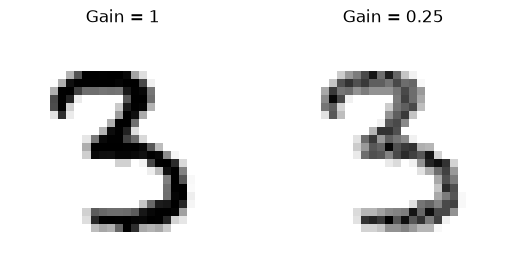

In [22]:
plt.figure(facecolor="w")
plt.subplot(1,2,1)
plt.imshow(spike_data_sample.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 1')

plt.subplot(1,2,2)
plt.imshow(spike_data_sample_gain.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 0.25')

plt.show()

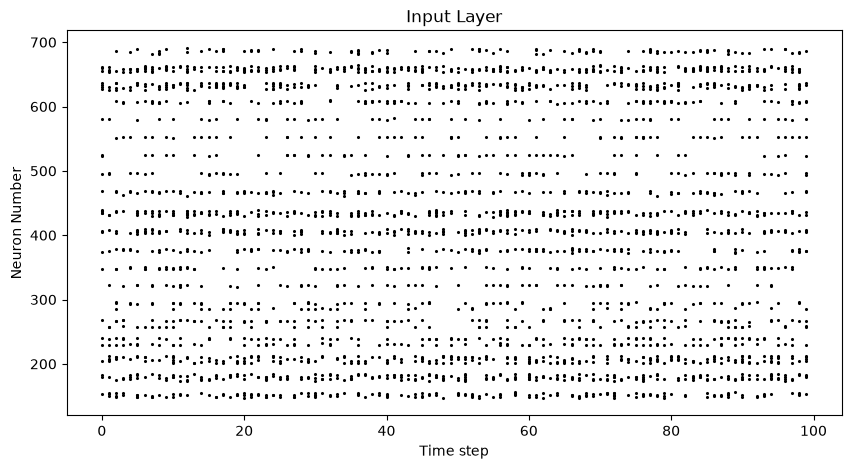

In [23]:
spike_data_sample_gain = spike_data_sample_gain.reshape((num_steps, -1))

# raster plot
fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data_sample_gain, ax, s=1.5, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

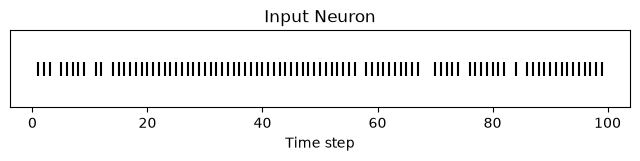

In [24]:
idx = 210  # index into 210th neuron

fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

splt.raster(spike_data_sample.reshape(num_steps, -1)[:, idx].unsqueeze(1), ax, s=100, c="black", marker="|")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.show()

Now we show that we can model the data instead of over probability, over time, here the spikes are temporally encoded.

In [25]:
def convert_to_time(data, tau=5, threshold=0.01):
  spike_time = tau * torch.log(data / (data - threshold))
  return spike_time

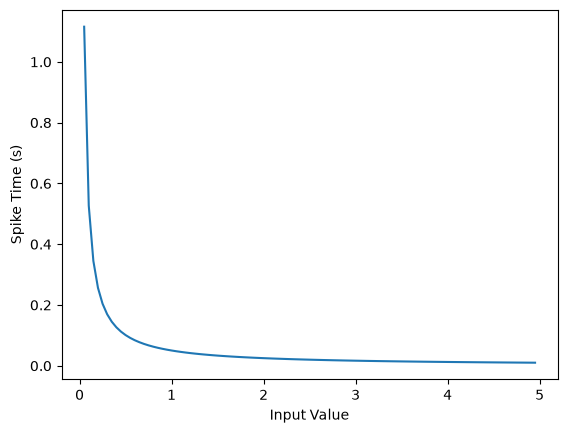

In [26]:
raw_input = torch.arange(0, 5, 0.05) # tensor from 0 to 5
spike_times = convert_to_time(raw_input)

plt.plot(raw_input, spike_times)
plt.xlabel('Input Value')
plt.ylabel('Spike Time (s)')
plt.show()

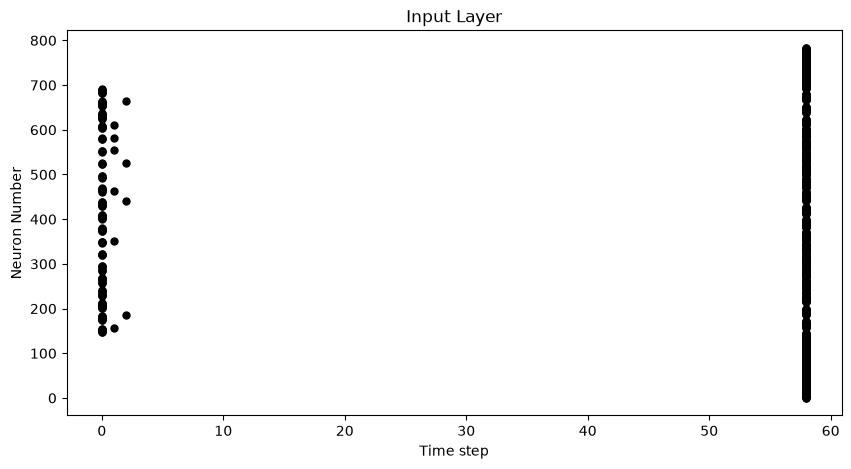

Saved image to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_latency_raster.mp4


In [27]:
spike_data = spikegen.latency(data_it, num_steps=num_steps, tau=5, threshold=0.01)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

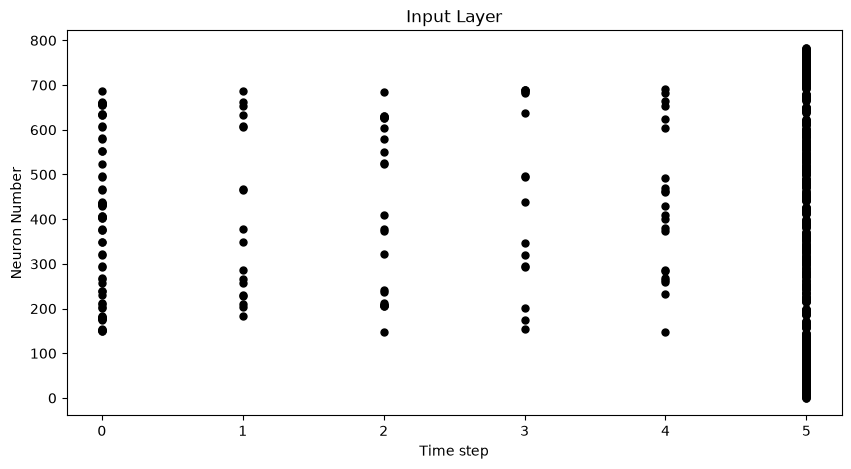

Saved image to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_latency_raster_linearized.mp4


In [28]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")
plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

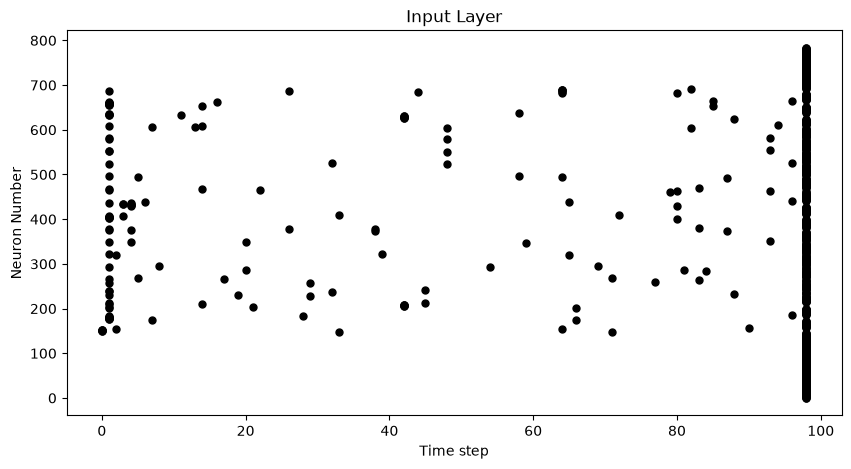

Saved image to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_latency_raster_linearized_normalized.mp4


In [29]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01,
                              normalize=True, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized_normalized.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

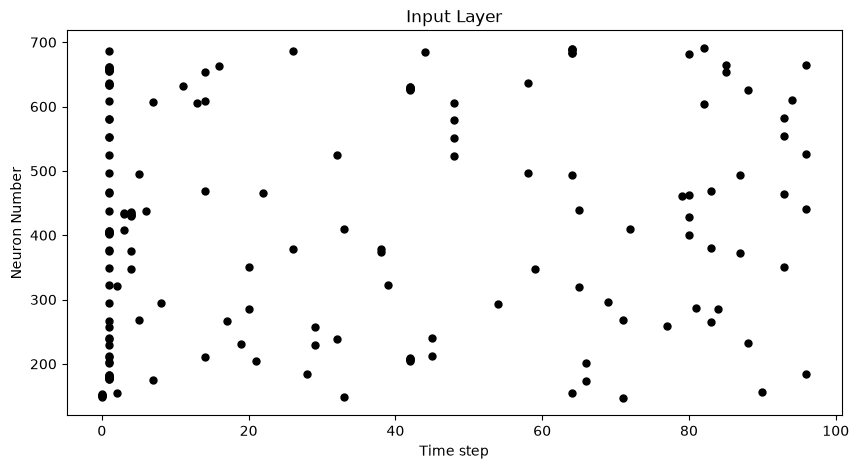

Saved image to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_latency_raster_linearized_normalized_clip.mp4


In [30]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01,
                              clip=True, normalize=True, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized_normalized_clip.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

In [31]:
spike_data_sample = spike_data[:, 0, 0]
render_figure(spike_data_sample, "spike_mnist_latency_animation_.mp4")

Saved animation to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_latency_animation_.mp4


Finally we do delta encoding, or difference encoding, like an event based activation.

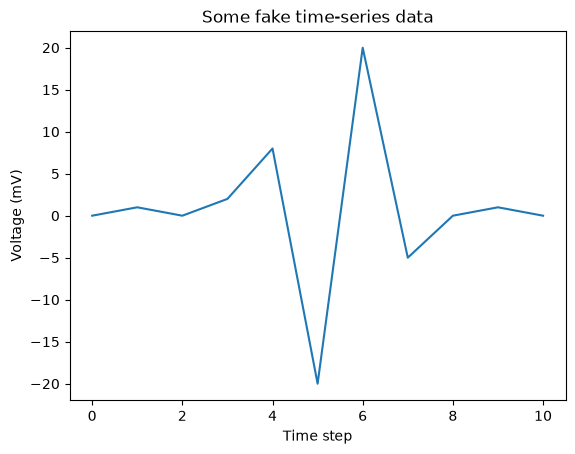

In [32]:
# Create a tensor with some fake time-series data
data = torch.Tensor([0, 1, 0, 2, 8, -20, 20, -5, 0, 1, 0])

# Plot the tensor
plt.plot(data)

plt.title("Some fake time-series data")
plt.xlabel("Time step")
plt.ylabel("Voltage (mV)")
plt.show()

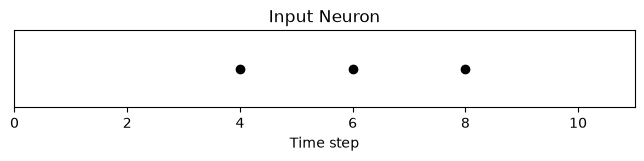

In [33]:
# Convert data
spike_data = spikegen.delta(data, threshold=4)

# Create fig, ax
fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

# Raster plot of delta converted data
splt.raster(spike_data, ax, c="black")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.xlim(0, len(data))
plt.show()

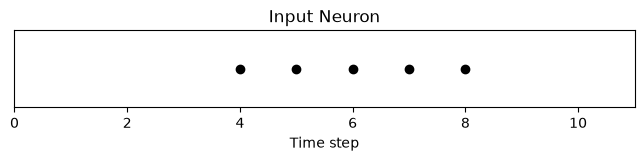

tensor([ 0.,  0.,  0.,  0.,  1., -1.,  1., -1.,  1.,  0.,  0.])


In [34]:
# Convert data
spike_data = spikegen.delta(data, threshold=4, off_spike=True)

# Create fig, ax
fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

# Raster plot of delta converted data
splt.raster(spike_data, ax, c="black")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.xlim(0, len(data))
plt.show()

print(spike_data)

In [35]:
# Create a random spike train
spike_prob = torch.rand((num_steps, 28, 28), dtype=dtype) * 0.5
spike_rand = spikegen.rate_conv(spike_prob)
render_figure(spike_rand, "spike_mnist_spike_generation_.mp4")

Saved animation to /home/tijje/Documents/RUG/Year 3/1A/Neural Networks/04 Project and assignments/SNN_Project-Neural_Networks-RUG-/report/figures/spike_mnist_spike_generation_.mp4


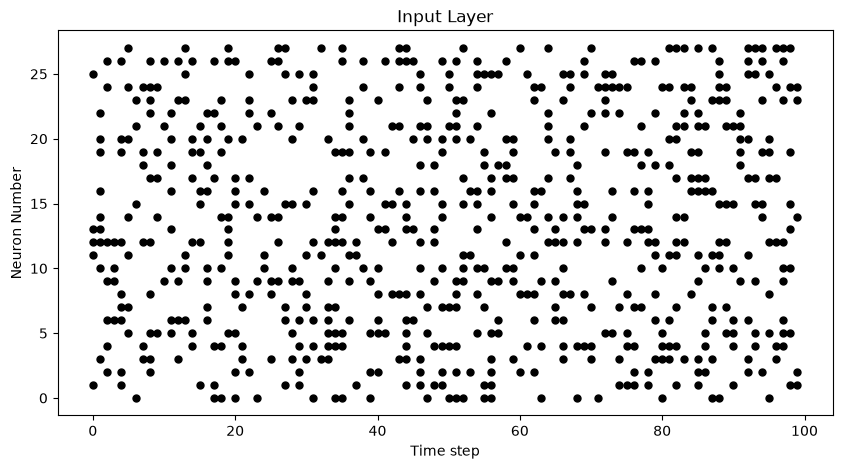

In [36]:
fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_rand[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

# Tutorial 2 - LIF Neuron Implementation

Supporting plotting functions

In [37]:
def plot_mem(mem, title="Membrane potential"):
    fig, ax = plt.subplots()
    ax.plot(torch.as_tensor(mem).detach().cpu())
    ax.set(xlabel="Time step", ylabel="Membrane potential", title=title)
    plt.show()
    return fig, ax


def plot_step_current_response(cur_in, mem_rec, step_onset, title="Step current response"):
    fig, axes = plt.subplots(2, 1, sharex=True)
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for ax in axes:
        ax.axvline(step_onset, color="gray", linestyle="--")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_current_pulse_response(
    cur_in, mem_rec, title="Current pulse response", vline1=None, vline2=None,
    ylim_max1=None, ylim_max2=None
):
    fig, axes = plt.subplots(2, 1, sharex=True)
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for boundary in (vline1, vline2):
        if boundary is not None:
            for ax in axes:
                ax.axvline(boundary, color="gray", linestyle="--")
    if ylim_max1 is not None:
        axes[0].set_ylim(top=ylim_max1)
    if ylim_max2 is not None:
        axes[1].set_ylim(top=ylim_max2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def compare_plots(
    cur_in1, cur_in2, cur_in3, mem_rec1, mem_rec2, mem_rec3,
    vline1, vline2, vline3, vline4, title="Current pulse comparison"
):
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
    for current, mem, label in zip(
        (cur_in1, cur_in2, cur_in3),
        (mem_rec1, mem_rec2, mem_rec3),
        ("Pulse 1", "Pulse 2", "Pulse 3"),
    ):
        axes[0].plot(torch.as_tensor(current).detach().cpu(), label=label)
        axes[1].plot(torch.as_tensor(mem).detach().cpu(), label=label)
    axes[0].set_ylabel("Input current")
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for ax in axes:
        for boundary in (vline1, vline2, vline3, vline4):
            ax.axvline(boundary, color="gray", linestyle="--", alpha=0.5)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_cur_mem_spk(
    cur_in, mem_rec, spk_rec, thr_line=None, vline=None,
    ylim_max1=None, ylim_max2=None, title="Current, membrane, and spikes"
):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set_ylabel("Membrane potential")
    spikes = torch.as_tensor(spk_rec).detach().cpu()
    splt.raster(spikes.reshape(len(spikes), -1), axes[2], s=100, c="black", marker="|")
    axes[2].set(xlabel="Time step", ylabel="Output spikes", yticks=[])
    if thr_line is not None:
        axes[1].axhline(thr_line, color="red", linestyle="--", label="Threshold")
        axes[1].legend()
    if vline is not None:
        for ax in axes:
            ax.axvline(vline, color="gray", linestyle="--")
    if ylim_max1 is not None:
        axes[0].set_ylim(top=ylim_max1)
    if ylim_max2 is not None:
        axes[1].set_ylim(top=ylim_max2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_spk_mem_spk(spk_in, mem_rec, spk_rec, title="Spike input response"):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    for ax, values, label in (
        (axes[0], spk_in, "Input spikes"),
        (axes[2], spk_rec, "Output spikes"),
    ):
        spikes = torch.as_tensor(values).detach().cpu()
        splt.raster(spikes.reshape(len(spikes), -1), ax, s=100, c="black", marker="|")
        ax.set(ylabel=label, yticks=[])
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set_ylabel("Membrane potential")
    axes[2].set_xlabel("Time step")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_reset_comparison(
    spk_in, mem_rec, spk_rec, mem_rec0, spk_rec0, title="Reset comparison"
):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    spikes = torch.as_tensor(spk_in).detach().cpu()
    splt.raster(spikes.reshape(len(spikes), -1), axes[0], s=100, c="black", marker="|")
    axes[0].set(ylabel="Input spikes", yticks=[])
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu(), label="Subtract reset")
    axes[1].plot(torch.as_tensor(mem_rec0).detach().cpu(), label="Zero reset")
    axes[1].set_ylabel("Membrane potential")
    axes[1].legend()
    output_spikes = torch.cat((
        torch.as_tensor(spk_rec).detach().cpu().reshape(len(spk_rec), -1),
        torch.as_tensor(spk_rec0).detach().cpu().reshape(len(spk_rec0), -1),
    ), dim=1)
    splt.raster(output_spikes, axes[2], s=100, c="black", marker="|")
    axes[2].set(xlabel="Time step", ylabel="Output spikes", yticks=[0, 1])
    axes[2].set_yticklabels(["Subtract", "Zero"])
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes

## Leaky neuron and current responses

Here we demonstrate the different the different neurons. We start with LIF, with the eulers method for solving the update for each step.

In [38]:
time_step = 1e-3 # time scale of 1 millisecond

def leaky_integrate_neuron(U, time_step=1e-3, I=0, R=5e7, C=1e-10):
  tau = R*C
  U = U + (time_step/tau)*(-U + I*R)
  return U

Here the membrain potential starts at 0.9V, with no injected input current from other neurons since I is default 0, and RC circuit is the default as well. It shows the leak over time.

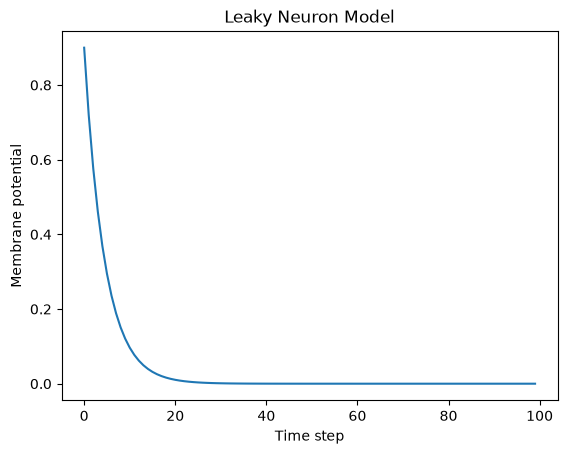

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Leaky Neuron Model'}, xlabel='Time step', ylabel='Membrane potential'>)

In [39]:
U = 0.9
U_trace = []  # keeps a record of U for plotting

for step in range(num_steps):
  U_trace.append(U)
  U = leaky_integrate_neuron(U)  # solve next step of U

plot_mem(U_trace, "Leaky Neuron Model")

SNNtorch does this itself without our crude implementation of the equation using snn.Lapiceque. Since this uses discrete time steps, we give how long each time step is using the default from before. 

In [40]:
R = 5
C = 1e-3
lif1 = snn.Lapicque(R=R, C=C, time_step=time_step) # leaky integrate and fire neuron, tau=5e-3

# Initialize membrane, input, and output
mem = torch.ones(1) * 0.9  # U=0.9 at t=0
cur_in = torch.zeros(num_steps, 1)  # I=0 for all t
spk_out = torch.zeros(1)  # Initialize output spikes

mem_rec = [mem] # A list to store a recording of membrane potential for graphing

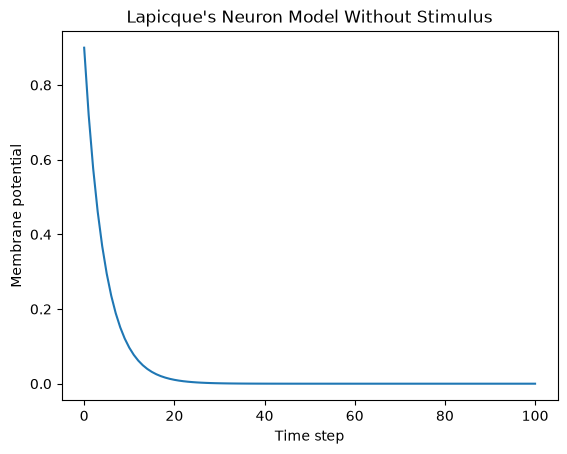

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': "Lapicque's Neuron Model Without Stimulus"}, xlabel='Time step', ylabel='Membrane potential'>)

In [41]:
# pass updated value of mem and cur_in[step]=0 at every time step
for step in range(num_steps):
  spk_out, mem = lif1(cur_in[step], mem)
  mem_rec.append(mem) # Store recordings of membrane potential

mem_rec = torch.stack(mem_rec) # convert the list of tensors into one tensor
plot_mem(mem_rec, "Lapicque's Neuron Model Without Stimulus") # pre-defined plotting function

Now we add an input current to the RC circuit Lapiceque, which is zero until step 10 then 1 for the rest of time.

In [42]:
# Initialize input current pulse
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(num_steps-10, 1)*0.1), 0)  # input current turns on at t=10

# Initialize membrane, output and recordings
mem = torch.zeros(1)  # membrane potential of 0 at t=0
spk_out = torch.zeros(1)  # neuron needs somewhere to sequentially dump its output spikes
mem_rec = [mem]

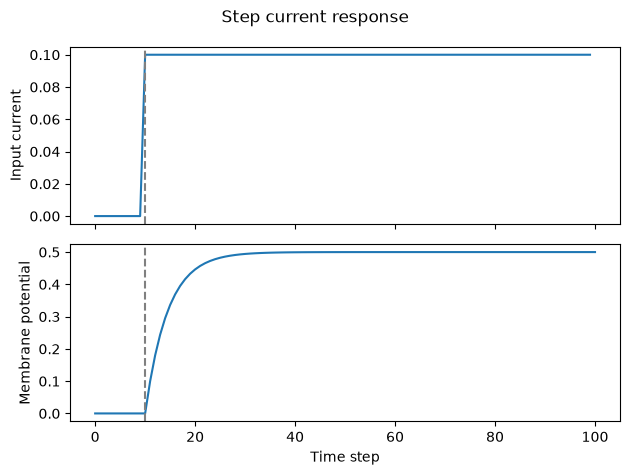

The calculated value of input pulse [A] x resistance [Ω] is: tensor([0.5000]) V
The simulated value of steady-state membrane potential is: 0.4999999403953552 V


In [43]:
# pass updated value of mem and cur_in[step] at every time step
for step in range(num_steps):
  spk_out, mem = lif1(cur_in[step], mem)
  mem_rec.append(mem)

# crunch -list- of tensors into one tensor
mem_rec = torch.stack(mem_rec)
plot_step_current_response(cur_in, mem_rec, 10)

print(f"The calculated value of input pulse [A] x resistance [Ω] is: {cur_in[11]*lif1.R} V")
print(f"The simulated value of steady-state membrane potential is: {mem_rec[num_steps][0]} V")

Now instead of constant input, we do a pulse input.

In [44]:
cur_in1 = torch.cat((torch.zeros(10, 1), torch.ones(20, 1)*(0.1), torch.zeros(num_steps, 1)), 0)  # input turns on at t=10, off at t=30
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec1 = [mem]

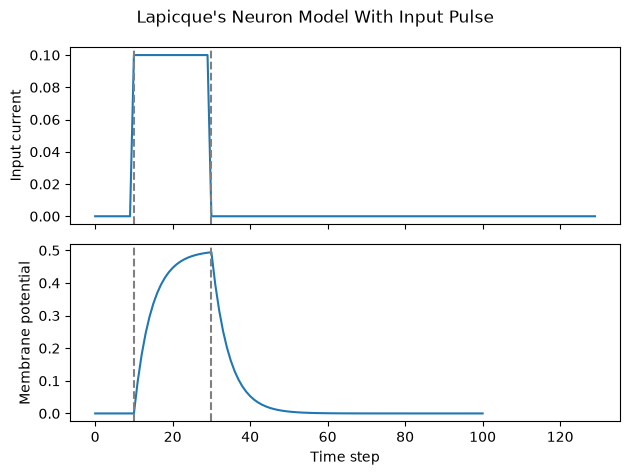

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [45]:
# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in1[step], mem)
  mem_rec1.append(mem)
mem_rec1 = torch.stack(mem_rec1)

plot_current_pulse_response(cur_in1, mem_rec1, "Lapicque's Neuron Model With Input Pulse",
                            vline1=10, vline2=30)

Now we shorten the time but keep the charge the same, so same energy shorter time.

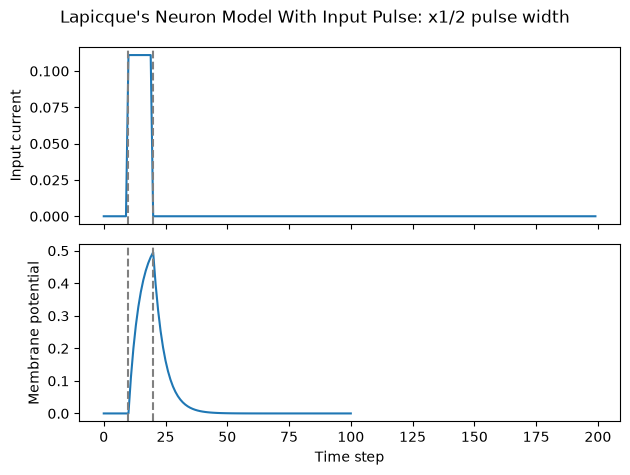

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [46]:
# Increase amplitude of current pulse; half the time.
cur_in2 = torch.cat((torch.zeros(10, 1), torch.ones(10, 1)*0.111, torch.zeros(180, 1)), 0)  # input turns on at t=10, off at t=20
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec2 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in2[step], mem)
  mem_rec2.append(mem)
mem_rec2 = torch.stack(mem_rec2)

plot_current_pulse_response(cur_in2, mem_rec2, "Lapicque's Neuron Model With Input Pulse: x1/2 pulse width",
                            vline1=10, vline2=20)

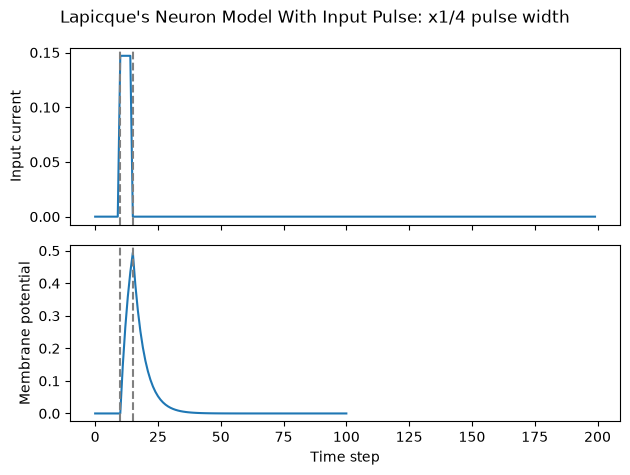

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [47]:
# Increase amplitude of current pulse; quarter the time.
cur_in3 = torch.cat((torch.zeros(10, 1), torch.ones(5, 1)*0.147, torch.zeros(185, 1)), 0)  # input turns on at t=10, off at t=15
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec3 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in3[step], mem)
  mem_rec3.append(mem)
mem_rec3 = torch.stack(mem_rec3)

plot_current_pulse_response(cur_in3, mem_rec3, "Lapicque's Neuron Model With Input Pulse: x1/4 pulse width",
                            vline1=10, vline2=15)

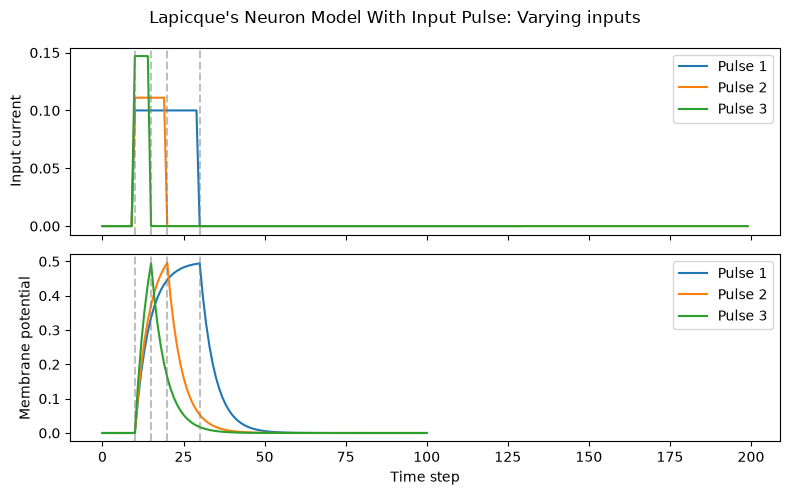

(<Figure size 800x500 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [48]:
compare_plots(cur_in1, cur_in2, cur_in3, mem_rec1, mem_rec2, mem_rec3, 10, 15,
              20, 30, "Lapicque's Neuron Model With Input Pulse: Varying inputs")

Finally, as this time approahces zero, the jump is instant.

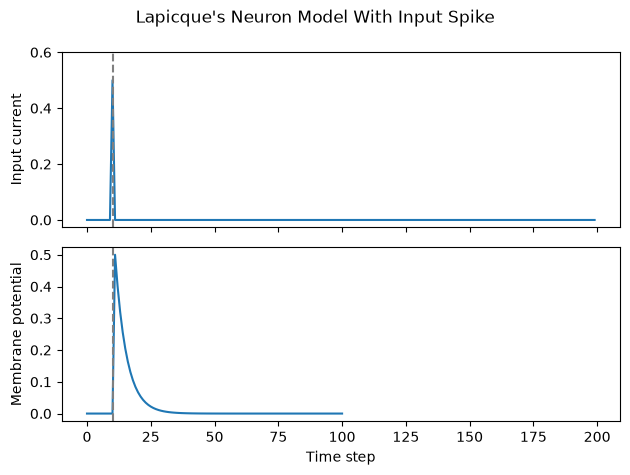

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [49]:
# Current spike input
cur_in4 = torch.cat((torch.zeros(10, 1), torch.ones(1, 1)*0.5, torch.zeros(189, 1)), 0)  # input only on for 1 time step
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec4 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in4[step], mem)
  mem_rec4.append(mem)
mem_rec4 = torch.stack(mem_rec4)

plot_current_pulse_response(cur_in4, mem_rec4, "Lapicque's Neuron Model With Input Spike",
                            vline1=10, ylim_max1=0.6)

Modify the crude equation we had before, this time if the membrane goes about a threshold it "spikes".

In [50]:
# R=5.1, C=5e-3 for illustrative purposes
def leaky_integrate_and_fire(mem, cur=0, threshold=1, time_step=1e-3, R=5.1, C=5e-3):
  tau_mem = R*C
  spk = (mem > threshold) # if membrane exceeds threshold, spk=1, else, 0
  mem = mem + (time_step/tau_mem)*(-mem + cur*R)
  return mem, spk

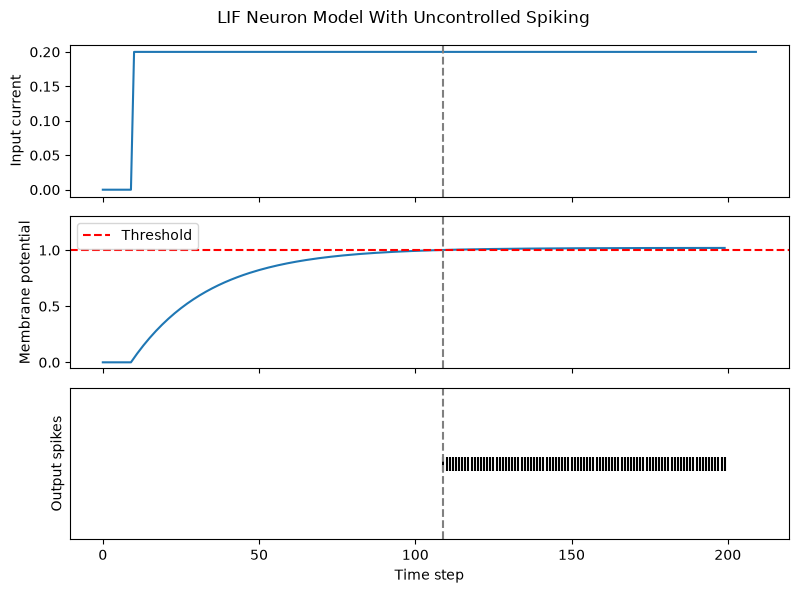

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [51]:
# Small step current input
cur_in = torch.cat((torch.zeros(10), torch.ones(num_steps+100)*0.2), 0)
mem = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron simulation
for step in range(num_steps+100):
  mem, spk = leaky_integrate_and_fire(mem, cur_in[step])
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="LIF Neuron Model With Uncontrolled Spiking")

Now instead of keeping spiking, we need a recovery period.

In [52]:
# LIF w/Reset mechanism
def leaky_integrate_and_fire(mem, cur=0, threshold=1, time_step=1e-3, R=5.1, C=5e-3):
  tau_mem = R*C
  spk = (mem > threshold)
  mem = mem + (time_step/tau_mem)*(-mem + cur*R) - spk*threshold  # every time spk=1, subtract the threhsold
  return mem, spk

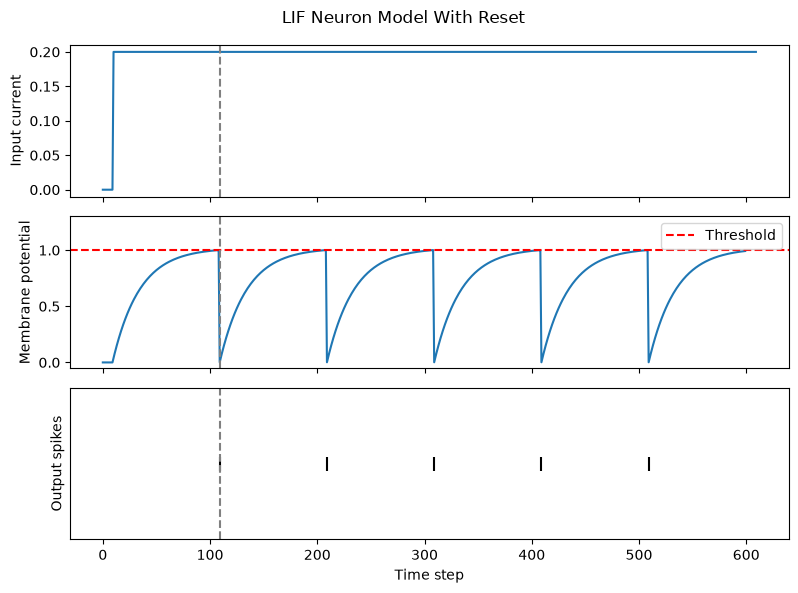

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [53]:
# Small step current input
cur_in = torch.cat((torch.zeros(10), torch.ones(num_steps+500)*0.2), 0)
mem = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron simulation
for step in range(num_steps+500):
  mem, spk = leaky_integrate_and_fire(mem, cur_in[step])
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="LIF Neuron Model With Reset")

Still, we can use the Lapicque neuron from snn

In [54]:
# Create the same neuron as before using snnTorch
lif2 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3)
print(f"Membrane potential time constant: {lif2.R * lif2.C:.3f}s")

Membrane potential time constant: 0.025s


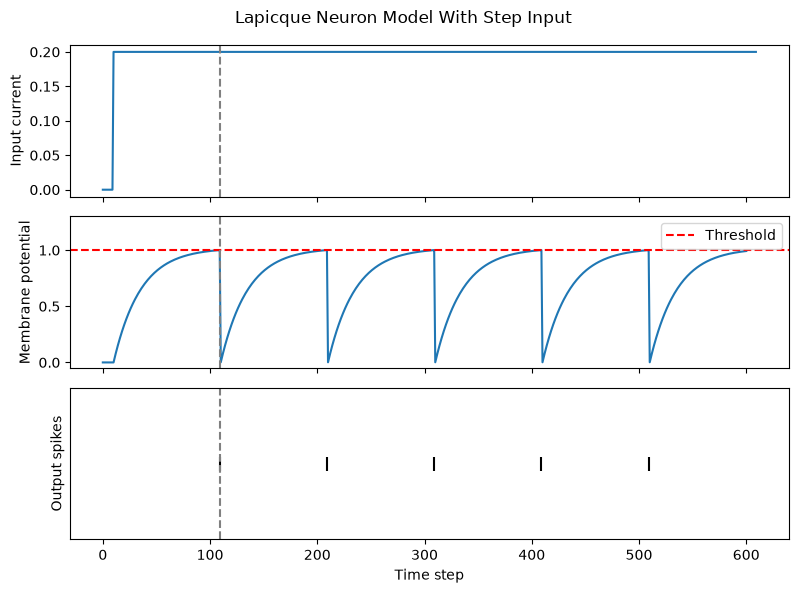

tensor([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.])


In [55]:
# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(num_steps+500, 1)*0.2), 0)
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Simulation run across 100 time steps.
for step in range(num_steps+500):
  spk_out, mem = lif2(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Step Input")
print(spk_rec[105:115].view(-1))

Here we increate the current supplied to increase the spiking rate

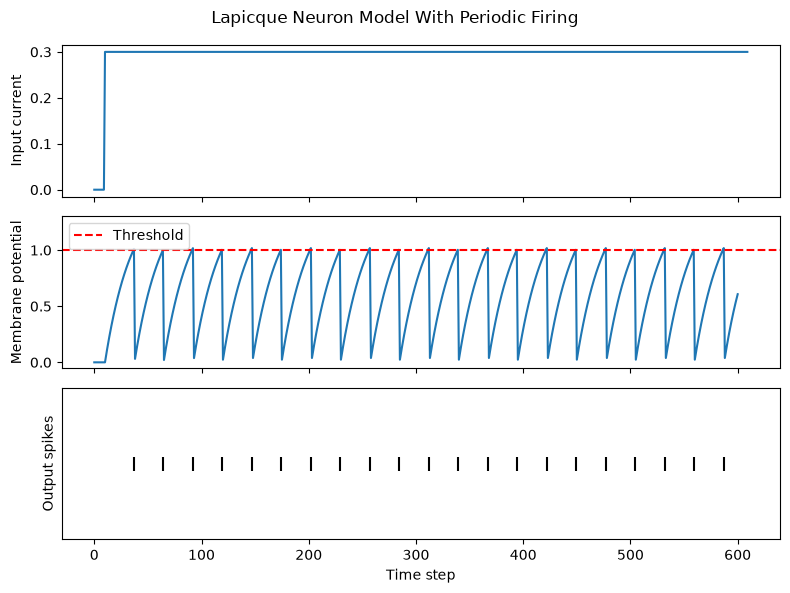

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [56]:
# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(num_steps+500, 1)*0.3), 0)  # increased current
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# neuron simulation
for step in range(num_steps+500):
  spk_out, mem = lif2(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)


plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Periodic Firing")

Here the same result can come from decreasing threshold, but the input stays the same as before, so now we have 4x the rate:

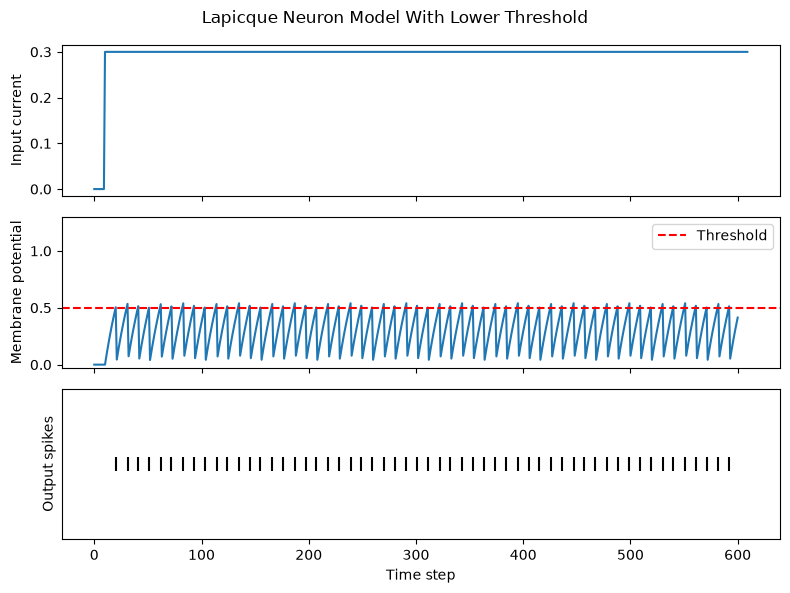

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [57]:
# neuron with halved threshold
lif3 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3, threshold=0.5)

# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(num_steps+500, 1)*0.3), 0)
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Neuron simulation
for step in range(num_steps+500):
  spk_out, mem = lif3(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=0.5, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Lower Threshold")

Now instead of simple inputs lets stream in spikes generated with the rate generation:

There are 41 total spikes out of 100 time steps.


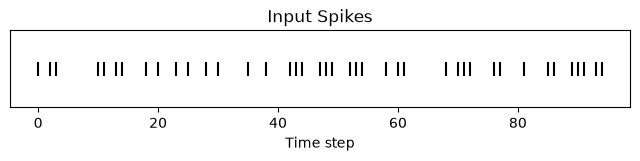

In [58]:
# Create a 1-D random spike train. Each element has a probability of 40% of firing.
spk_in = spikegen.rate_conv(torch.ones((num_steps,1)) * 0.40)
print(f"There are {int(sum(spk_in))} total spikes out of {len(spk_in)} time steps.")

fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

splt.raster(spk_in.reshape(num_steps, -1), ax, s=100, c="black", marker="|")
plt.title("Input Spikes")
plt.xlabel("Time step")
plt.yticks([])
plt.show()

Now we feed this into the laplace neuron to see what it does

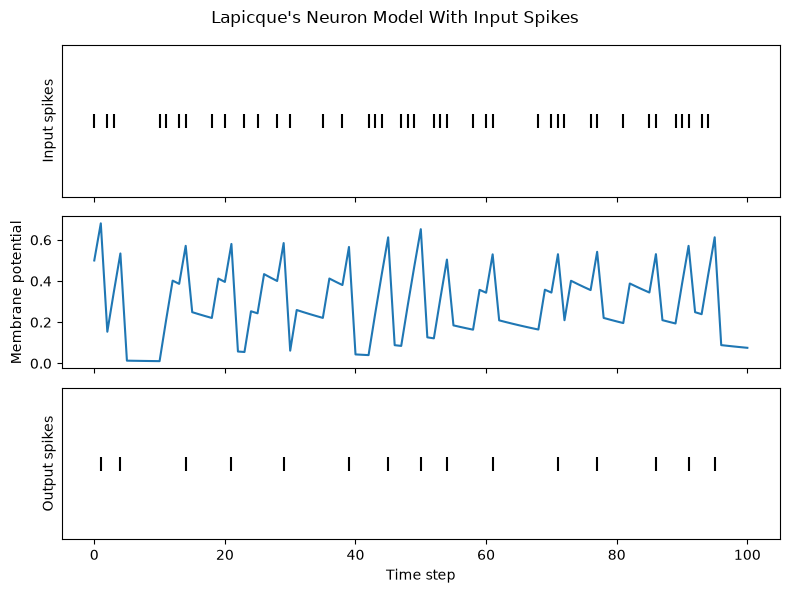

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input spikes'>, <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [59]:
# Initialize inputs and outputs
mem = torch.ones(1)*0.5
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Neuron simulation
for step in range(num_steps):
  spk_out, mem = lif3(spk_in[step], mem)
  spk_rec.append(spk_out)
  mem_rec.append(mem)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_spk_mem_spk(spk_in, mem_rec, spk_rec, "Lapicque's Neuron Model With Input Spikes")

We did the subtraction of the threshold to simulate hyperlpolrization, but there are other ways as well to implement the reset mechanism:

- reset by subtraction (default) − subtract the threshold from the membrane potential each time a spike is generated;

- reset to zero − force the membrane potential to zero each time a spike is generated.

- no reset − do nothing, and let the firing go potentially uncontrolled.

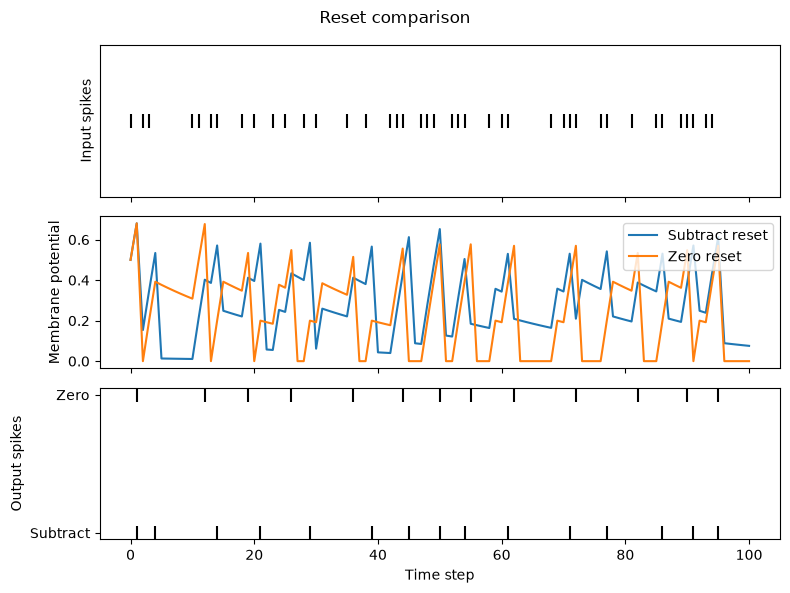

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input spikes'>, <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [60]:
# Neuron with reset_mechanism set to "zero"
lif4 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3, threshold=0.5, reset_mechanism="zero")

# Initialize inputs and outputs
# Reuse spk_in so both reset modes receive the same input spikes.
mem = torch.ones(1)*0.5
spk_out = torch.zeros(1)
mem_rec0 = [mem]
spk_rec0 = [spk_out]

# Neuron simulation
for step in range(num_steps):
  spk_out, mem = lif4(spk_in[step], mem)
  spk_rec0.append(spk_out)
  mem_rec0.append(mem)

# convert lists to tensors
mem_rec0 = torch.stack(mem_rec0)
spk_rec0 = torch.stack(spk_rec0)

plot_reset_comparison(spk_in, mem_rec, spk_rec, mem_rec0, spk_rec0)

# Tutorial 3 - FFSNN

Assume we simplify the previous neuron to a decay rate beta, threshold, weights to learn which determine the strength of the input, the input as X(t+1), and previous spike and membrane potential.

In [61]:
def leaky_integrate_and_fire(mem, x, w, beta, threshold=1):
  spk = (mem > threshold) # if membrane exceeds threshold, spk=1, else, 0
  mem = beta * mem + w*x - spk*threshold
  return spk, mem

# set neuronal parameters
delta_t = torch.tensor(1e-3)
tau = torch.tensor(5e-3)
beta = torch.exp(-delta_t/tau)
print(f"The decay rate is: {beta:.3f}")

The decay rate is: 0.819


In [62]:
spk_in_2 = spikegen.rate_conv(torch.ones((num_steps+500,1)) * 0.40)

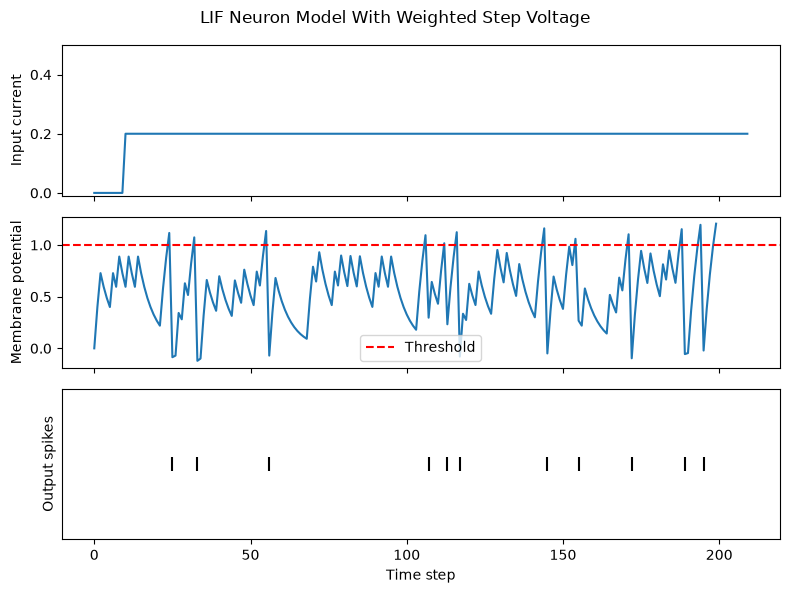

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [63]:
# initialize inputs/outputs + small step current input
x = torch.cat((torch.zeros(10), torch.ones(num_steps+100)*0.5), 0)
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron parameters
w = 0.4
beta = 0.819

# neuron simulation
for step in range(num_steps+100):
  spk, mem = leaky_integrate_and_fire(mem, spk_in_2[step], w=w, beta=beta)
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(x*w, mem_rec, spk_rec, thr_line=1,ylim_max1=0.5,
                 title="LIF Neuron Model With Weighted Step Voltage")

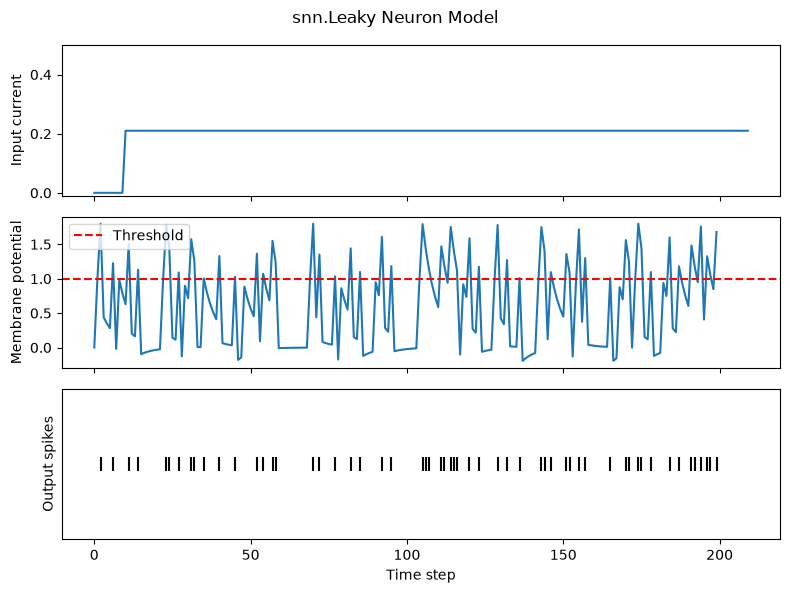

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [64]:
lif3 = snn.Leaky(beta=0.8, reset_mechanism='subtract')

# Small step current input
w=0.21
cur_in = torch.cat((torch.zeros(10), torch.ones(num_steps+100)*w), 0)
mem = torch.zeros(1)
spk = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron simulation
for step in range(num_steps+100):
  spk, mem = lif3(spk_in_2[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, ylim_max1=0.5,
                 title="snn.Leaky Neuron Model")

In [65]:
# layer parameters
num_inputs = 784
num_hidden = 1000
num_outputs = 10
beta = 0.99

# initialize layers
fc1 = nn.Linear(num_inputs, num_hidden)
lif1 = snn.Leaky(beta=beta)
fc2 = nn.Linear(num_hidden, num_outputs)
lif2 = snn.Leaky(beta=beta)

# Initialize hidden states
mem1 = lif1.init_leaky()
mem2 = lif2.init_leaky()

# record outputs
mem2_rec = []
spk1_rec = []
spk2_rec = []

In [66]:
spk_in = spikegen.rate_conv(torch.rand((200, 784))).unsqueeze(1)
print(f"Dimensions of spk_in: {spk_in.size()}")

Dimensions of spk_in: torch.Size([200, 1, 784])


In [67]:
def plot_snn_spikes(spk_in, spk1_rec, spk2_rec, title):
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

    for ax, spikes, label in zip(
        axes,
        (spk_in, spk1_rec, spk2_rec),
        ("Input Spikes", "Hidden Layer", "Output Spikes"),
    ):
        spikes = spikes.detach().cpu().reshape(spikes.shape[0], -1)
        splt.raster(spikes, ax, s=1, c="black")
        ax.set_ylabel(label)

    axes[0].set_title(title)
    axes[-1].set_xlabel("Time step")
    plt.tight_layout()
    plt.show()

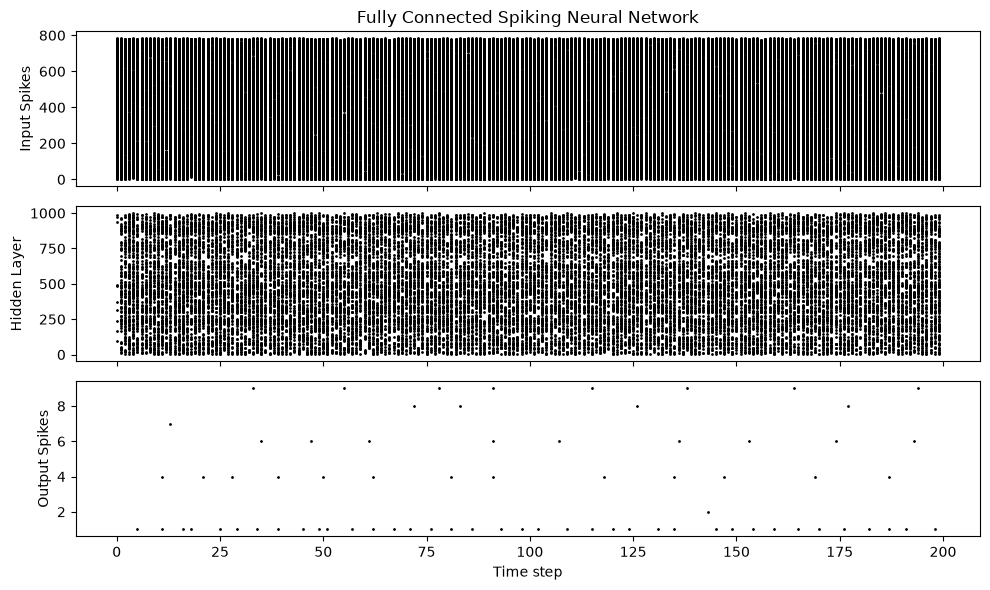

In [68]:
for step in range(num_steps+100):
    cur1 = fc1(spk_in[step]) # post-synaptic current <-- spk_in x weight
    spk1, mem1 = lif1(cur1, mem1) # mem[t+1] <--post-syn current + decayed membrane
    cur2 = fc2(spk1)
    spk2, mem2 = lif2(cur2, mem2)

    mem2_rec.append(mem2)
    spk1_rec.append(spk1)
    spk2_rec.append(spk2)

# convert lists to tensors
mem2_rec = torch.stack(mem2_rec)
spk1_rec = torch.stack(spk1_rec)
spk2_rec = torch.stack(spk2_rec)

plot_snn_spikes(spk_in, spk1_rec, spk2_rec, "Fully Connected Spiking Neural Network")

findfont: Failed to find font weight black for DejaVu Sans, now using 700.


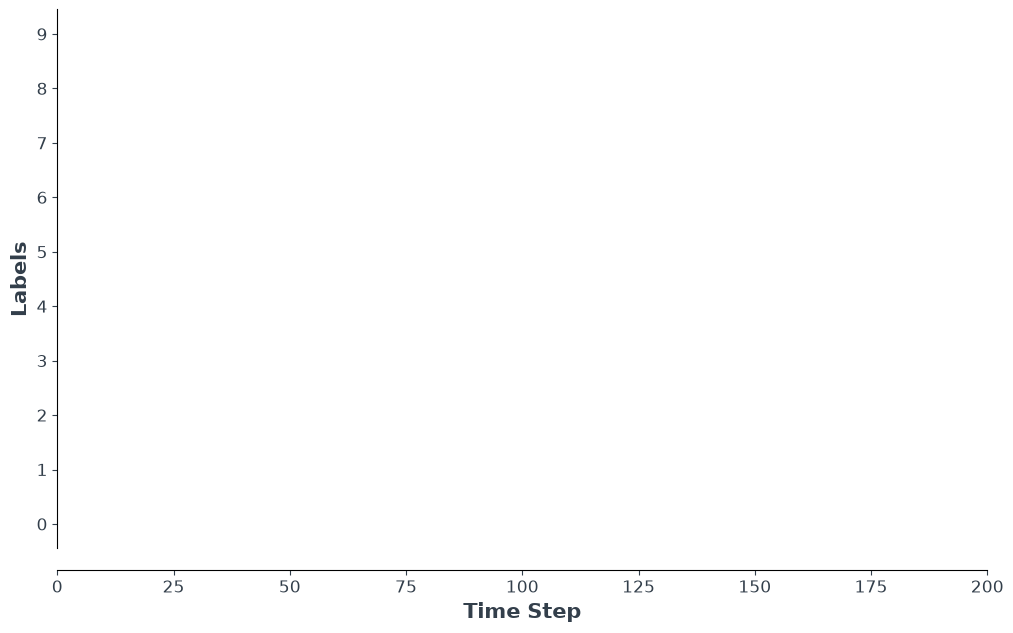

In [69]:
from IPython.display import HTML

fig, ax = plt.subplots(facecolor='w', figsize=(12, 7))
labels=['0', '1', '2', '3', '4', '5', '6', '7', '8','9']
spk2_rec = spk2_rec.squeeze(1).detach().cpu()

# plt.rcParams['animation.ffmpeg_path'] = 'C:\\path\\to\\your\\ffmpeg.exe'

#  Plot spike count histogram
anim = splt.spike_count(spk2_rec, fig, ax, labels=labels, animate=True)
HTML(anim.to_html5_video())
# anim.save("spike_bar.mp4")

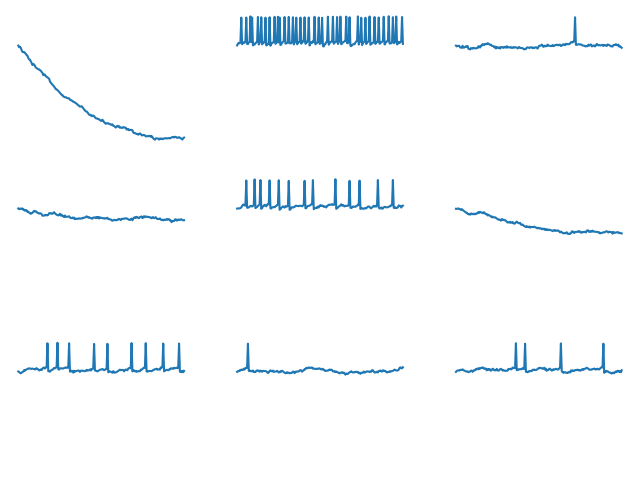

In [70]:
# plot membrane potential traces
splt.traces(mem2_rec.squeeze(1), spk=spk2_rec.squeeze(1))
fig = plt.gcf()
fig.set_size_inches(8, 6)

# Tutorial 4 2nd Order Spiking Neuron Models

Conductance based LIF-model using synaptic current

In [72]:
# Temporal dynamics
alpha = 0.9
beta = 0.8
num_steps = 200

# Initialize 2nd-order LIF neuron
lif1 = snn.Synaptic(alpha=alpha, beta=beta)

In [74]:
def plot_spk_cur_mem_spk(
    spk_in, syn_rec, mem_rec, spk_rec, title="Synaptic neuron response"
):
    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 8))

    for ax, values, label in (
        (axes[0], spk_in, "Input spikes"),
        (axes[3], spk_rec, "Output spikes"),
    ):
        spikes = torch.as_tensor(values).detach().cpu()
        splt.raster(
            spikes.reshape(len(spikes), -1),
            ax, s=100, c="black", marker="|"
        )
        ax.set(ylabel=label, yticks=[])

    axes[1].plot(torch.as_tensor(syn_rec).detach().cpu())
    axes[1].set_ylabel("Synaptic current")

    axes[2].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[2].set_ylabel("Membrane potential")
    axes[3].set_xlabel("Time step")

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes

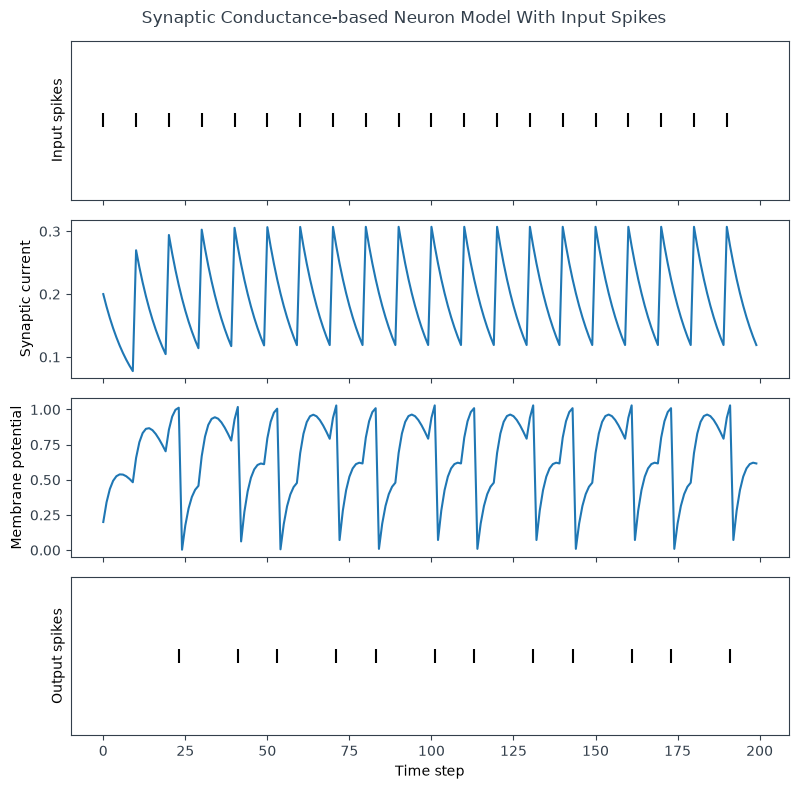

(<Figure size 800x800 with 4 Axes>,
 array([<Axes: ylabel='Input spikes'>, <Axes: ylabel='Synaptic current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [75]:
# Periodic spiking input, spk_in = 0.2 V
w = 0.2
spk_period = torch.cat((torch.ones(1)*w, torch.zeros(9)), 0)
spk_in = spk_period.repeat(20)

# Initialize hidden states and output
syn, mem = lif1.init_synaptic()
spk_out = torch.zeros(1)
syn_rec = []
mem_rec = []
spk_rec = []

# Simulate neurons
for step in range(num_steps):
  spk_out, syn, mem = lif1(spk_in[step], syn, mem)
  spk_rec.append(spk_out)
  syn_rec.append(syn)
  mem_rec.append(mem)

# convert lists to tensors
spk_rec = torch.stack(spk_rec)
syn_rec = torch.stack(syn_rec)
mem_rec = torch.stack(mem_rec)

plot_spk_cur_mem_spk(spk_in, syn_rec, mem_rec, spk_rec,
                     "Synaptic Conductance-based Neuron Model With Input Spikes")